In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Model Package
from sklearn.linear_model import LogisticRegression
# Train Test Package
from sklearn.model_selection import train_test_split
# Preprocessing Package
from sklearn.preprocessing import StandardScaler
# Metrics
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, roc_auc_score

In [2]:
df = pd.read_csv('Dataset/Cardiovascular_Disease.csv')
df.head()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0


## Data Cleaning

In [3]:
# Convert age from days to years
df['age'] = df['age']//365

In [4]:
# Removing Outliers
# sns.boxplot(df['height']) # 150 - 185
# sns.boxplot(df['weight'])# 45 - 120
# sns.boxplot(df['ap_hi']) # 90 - 190
# sns.boxplot(df['ap_lo']) # 50 - 90
df = df[
    (df['height'].between(150, 185)) &
    (df['weight'].between(45, 120)) & 
    (df['ap_hi'].between(90, 190)) &
    (df['ap_lo'].between(50, 90))
]

## Feature and Target

In [5]:
features = ['age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo','cholesterol', 'gluc', 
            'smoke', 'alco', 'active']
target = 'cardio'

In [6]:
X = df[features]
Y = df[target]

## Train Test Split

In [7]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42, stratify=Y
)

## Feature Scaling

In [8]:
scaler = StandardScaler()
X_train_scale = scaler.fit_transform(X_train)
X_test_scale = scaler.transform(X_test)

## Model Implementation

In [9]:
model = LogisticRegression(
    solver = 'lbfgs',
    class_weight='balanced',
    random_state=42
)

In [10]:
model.fit(X_train_scale, Y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default

In [31]:
Y_pred = model.predict(X_test_scale)
Y_pred

array([0, 0, 1, ..., 0, 1, 0], shape=(12263,))

## Metrics

In [12]:
cr = classification_report(Y_test, Y_pred)
cm = confusion_matrix(Y_test, Y_pred)

In [13]:
print(cr)

              precision    recall  f1-score   support

           0       0.72      0.76      0.74      6538
           1       0.71      0.67      0.69      5725

    accuracy                           0.72     12263
   macro avg       0.72      0.71      0.71     12263
weighted avg       0.72      0.72      0.72     12263



In [ ]:
'''
- Macro Avg: (val1 + val2 + ... + val_n) / num_of_classes
- Weighted Avg: (val1 * support) + (val2 * support) + ... + (val_n * support) / total_support
'''

# macro = (0.76 + 0.67)/2
# macro

# weight = ((0.76 * 6538) + (0.67 * 5725)) / 12263
# weight

In [14]:
print(cm)

[[4983 1555]
 [1911 3814]]


In [23]:
tn, fp, fn, tp = cm.ravel()
print(f'True Negative: {tn}')
print(f'False Positive: {fp}')
print(f'False Negative: {fn}')
print(f'True Positive: {tp}')

True Negative: 4983
False Positive: 1555
False Negative: 1911
True Positive: 3814


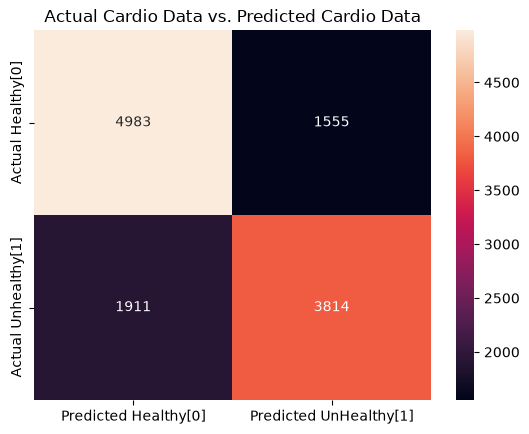

In [28]:
sns.heatmap(cm, annot=True, fmt='1.0f', xticklabels=['Predicted Healthy[0]', 'Predicted UnHealthy[1]'],
           yticklabels = ['Actual Healthy[0]', 'Actual Unhealthy[1]'])
plt.title('Actual Cardio Data vs. Predicted Cardio Data')
plt.show()

## Calculation for ROC-AUC Curve

### Probability Calculation

In [35]:
Y_prob = model.predict_proba(X_test_scale)[:,1]
Y_prob

array([0.46152872, 0.29832836, 0.74895384, ..., 0.28332823, 0.73706327,
       0.2283298 ], shape=(12263,))

### Roc and Auc Values

In [43]:
fpr, tpr, threshold = roc_curve(Y_test, Y_prob)
auc_score = roc_auc_score(Y_test, Y_prob)

print(f'False Positive Rate: {fpr}')
print(f'True Positive Rate: {tpr}')
print(f'Threshold: {threshold}')

print(f'AUC Score: {auc_score}')

False Positive Rate: [0.         0.         0.         ... 0.99694096 0.99694096 1.        ]
True Positive Rate: [0.00000000e+00 1.74672489e-04 8.73362445e-04 ... 9.99825328e-01
 1.00000000e+00 1.00000000e+00]
Threshold: [       inf 0.99568182 0.99225596 ... 0.03822439 0.03758642 0.02394927]
AUC Score: 0.7780802857597038


### Calculation of Actual Threshold Position

In [52]:
j_score = tpr - fpr
best_idx = np.argmax(j_score)

best_tpr = tpr[best_idx]
best_fpr = fpr[best_idx]
best_threshold = threshold[best_idx]

### ROC AUC Diagram

In [49]:
plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1])
plt.scatter(best_fpr, best_tpr)
plt.close()

## Setting New Calcuated Threshold for Prediction

In [53]:
Y_pred_prob = (Y_prob >= best_threshold).astype(int)
Y_pred_prob

array([0, 0, 1, ..., 0, 1, 0], shape=(12263,))

In [55]:
new_cr = classification_report(Y_test, Y_pred_prob)
new_cm = confusion_matrix(Y_test, Y_pred_prob)

print(new_cr)

              precision    recall  f1-score   support

           0       0.73      0.76      0.74      6538
           1       0.71      0.67      0.69      5725

    accuracy                           0.72     12263
   macro avg       0.72      0.72      0.72     12263
weighted avg       0.72      0.72      0.72     12263



In [56]:
print(new_cm)

[[4950 1588]
 [1862 3863]]
